# Sustainability Experiment Analysis
## Baseline vs Data Reuse — Energy, Throughput, Duration

In [23]:
import os
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from pathlib import Path

plt.rcParams.update({
    'font.size': 12,
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'figure.dpi': 150,
    'axes.grid': True,
    'grid.alpha': 0.3
})
print('Libraries loaded')

Libraries loaded


## 1. Configure Paths

In [25]:
# ── Update these paths to your local data folders ──────────────────────────
BASE_DIR = Path("~/Desktop/paper_experiments").expanduser()

EXPERIMENTS = {
    # Baseline
    "Baseline U2": BASE_DIR / "baseline_sequential" / "nextflow_rnaseq_partial_resume_2026_05_28_06_56_27_df3720c9",
    "Baseline U4": BASE_DIR / "baseline_sequential" / "nextflow_rnaseq_partial_resume_2026_05_28_08_23_15_380543a9",

    # Data Reuse U2
    "Reuse U2 10%": BASE_DIR / "reuse_sequential" / "nextflow_rnaseq_partial_resume_2026_05_27_10_34_11_31e60571",
    "Reuse U2 20%": BASE_DIR / "reuse_sequential" / "nextflow_rnaseq_partial_resume_2026_05_27_12_07_32_3d7b68ca",
    "Reuse U2 50%": BASE_DIR / "reuse_sequential" / "nextflow_rnaseq_partial_resume_2026_05_27_13_53_11_2e5a48b1",

    # Data Reuse U4
    "Reuse U4 10%": BASE_DIR / "reuse_sequential" / "nextflow_rnaseq_partial_resume_2026_05_27_15_19_12_fb52d4d4",
    "Reuse U4 20%": BASE_DIR / "reuse_sequential" / "nextflow_rnaseq_partial_resume_2026_05_27_18_29_51_f387afe0",
    "Reuse U4 50%": BASE_DIR / "reuse_sequential" / "nextflow_rnaseq_partial_resume_2026_05_27_22_10_43_9bb8ec96",
}

def load_run_json(folder):
    run_file = Path(folder) / "run.json"
    if run_file.exists():
        return json.loads(run_file.read_text())
    return None

def load_csv(folder, name):
    path = Path(folder) / "data" / name
    if path.exists():
        return pd.read_csv(path)
    return None

# Verify all experiment folders exist
for name, folder in EXPERIMENTS.items():
    rj = load_run_json(folder)
    if rj:
        print(f"✅ {name}: duration={rj.get('treatment_duration', 'N/A'):.0f}s")
    else:
        print(f"❌ {name}: not found at {folder}")

✅ Baseline U2: duration=5147s
✅ Baseline U4: duration=10373s
✅ Reuse U2 10%: duration=4937s
✅ Reuse U2 20%: duration=4914s
✅ Reuse U2 50%: duration=3952s
✅ Reuse U4 10%: duration=9653s
✅ Reuse U4 20%: duration=9077s
✅ Reuse U4 50%: duration=6673s


## 2. Load Energy and Duration Data

In [26]:
def get_total_energy_joules(folder):
    """Integrate watts over treatment period. step=10s"""
    df = load_csv(folder, "kepler_node_cpu_power_sum.csv")
    if df is not None and not df.empty:
        col = 'kepler_node_cpu_power_sum'
        if 'treatment' in df.columns:
            df = df[df['treatment'] == 'Treatment']
        return df[col].sum() * 10  # watts × 10s = joules
    return None

def get_treatment_duration(folder):
    rj = load_run_json(folder)
    if rj:
        return rj.get('treatment_duration', None)
    return None

tasks_per_user = 548

results = []
for name, folder in EXPERIMENTS.items():
    energy = get_total_energy_joules(folder)
    duration = get_treatment_duration(folder)
    u = 2 if 'U2' in name else 4
    dur_min = duration / 60 if duration else None
    throughput = (u * tasks_per_user) / dur_min if dur_min else None
    results.append({
        'experiment': name,
        'users': u,
        'energy_joules': energy,
        'duration_s': duration,
        'duration_min': dur_min,
        'throughput_tasks_min': throughput,
    })

df_results = pd.DataFrame(results)
print(df_results[['experiment', 'energy_joules', 'duration_min', 'throughput_tasks_min']].to_string(index=False))

  experiment  energy_joules  duration_min  throughput_tasks_min
 Baseline U2  214994.246659     85.782396             12.776514
 Baseline U4  432183.213727    172.888847             12.678666
Reuse U2 10%  205876.000566     82.288131             13.319053
Reuse U2 20%  200400.918843     81.895873             13.382848
Reuse U2 50%  164672.364339     65.863536             16.640467
Reuse U4 10%  405157.360542    160.883493             13.624766
Reuse U4 20%  379589.154530    151.285818             14.489131
Reuse U4 50%  276942.090330    111.211528             19.710187


## 3. Plot 1 — Total Energy Comparison

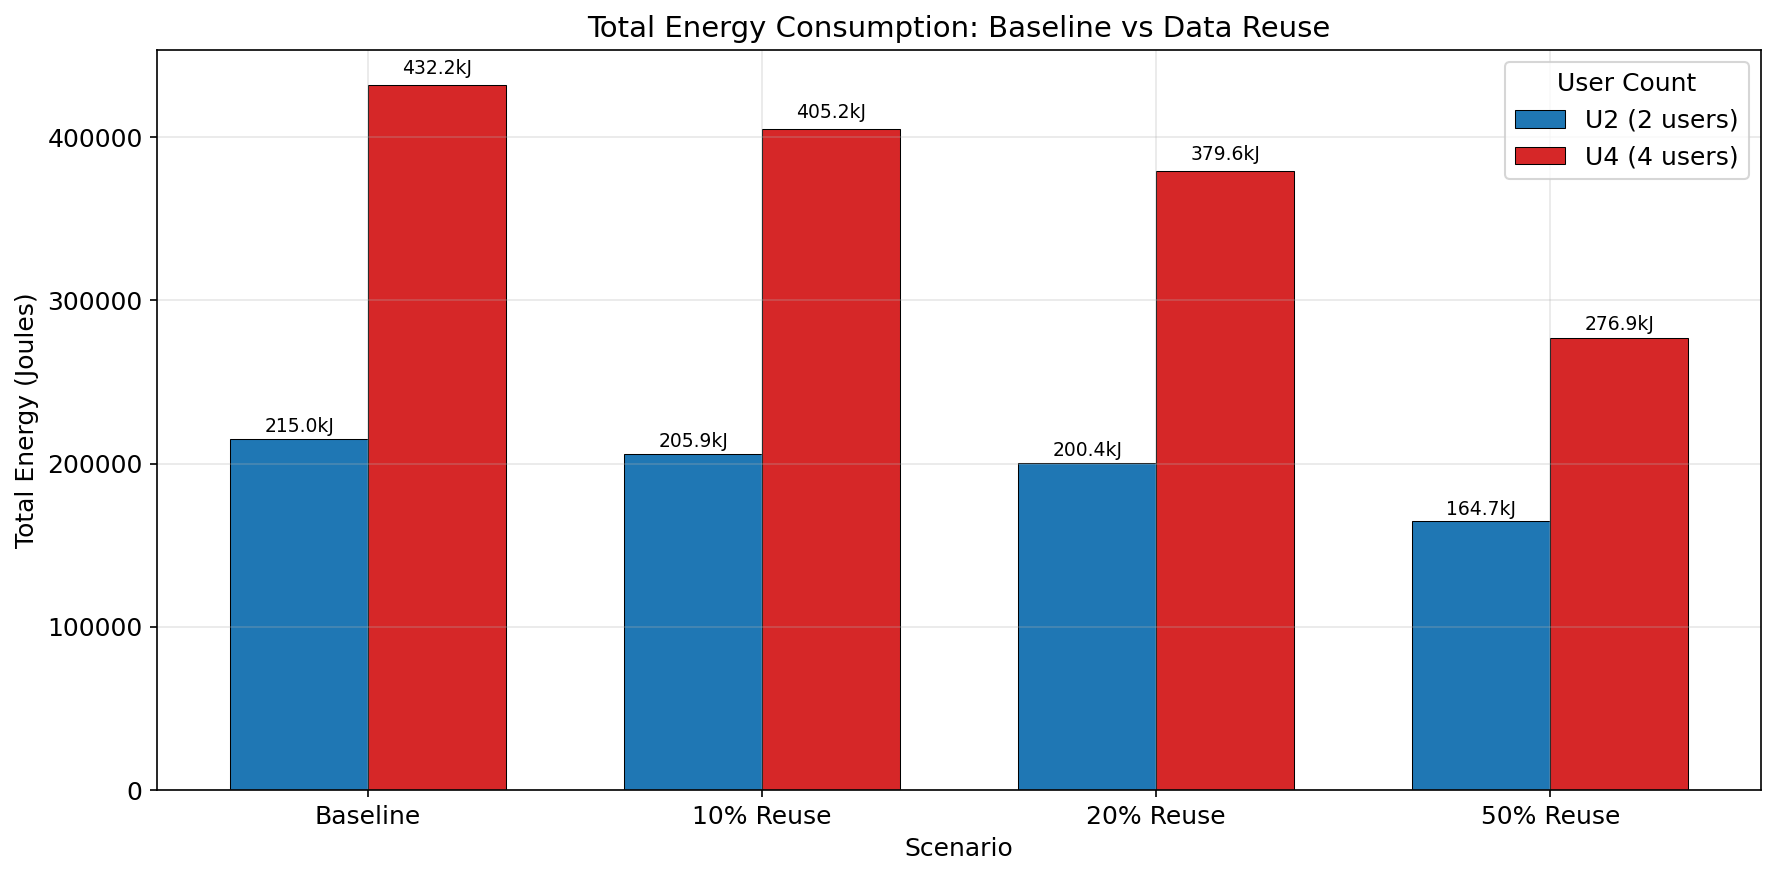

Saved: energy_comparison.pdf


In [35]:
fig, ax = plt.subplots(figsize=(12, 6))

scenarios = ['Baseline', '10% Reuse', '20% Reuse', '50% Reuse']
exp_keys_u2 = ['Baseline U2', 'Reuse U2 10%', 'Reuse U2 20%', 'Reuse U2 50%']
exp_keys_u4 = ['Baseline U4', 'Reuse U4 10%', 'Reuse U4 20%', 'Reuse U4 50%']

def get_val(df, exp, col):
    row = df[df['experiment'] == exp]
    if not row.empty and not pd.isna(row[col].values[0]):
        return row[col].values[0]
    return 0

energy_u2 = [get_val(df_results, k, 'energy_joules') for k in exp_keys_u2]
energy_u4 = [get_val(df_results, k, 'energy_joules') for k in exp_keys_u4]

x = np.arange(len(scenarios))
width = 0.35
colors_u2 = ['#1f77b4', '#1f77b4', '#1f77b4', '#1f77b4']
colors_u4 = ['#d62728', '#d62728', '#d62728', '#d62728']

bars1 = ax.bar(x - width/2, energy_u2, width, label='U2 (2 users)', color=colors_u2, edgecolor='black', linewidth=0.5)
bars2 = ax.bar(x + width/2, energy_u4, width, label='U4 (4 users)', color=colors_u4, edgecolor='black', linewidth=0.5)

for bar in bars1:
    h = bar.get_height()
    if h > 0:
        ax.text(bar.get_x() + bar.get_width()/2., h * 1.01, f'{h/1000:.1f}kJ', ha='center', va='bottom', fontsize=9)
for bar in bars2:
    h = bar.get_height()
    if h > 0:
        ax.text(bar.get_x() + bar.get_width()/2., h * 1.01, f'{h/1000:.1f}kJ', ha='center', va='bottom', fontsize=9)

ax.set_xlabel('Scenario')
ax.set_ylabel('Total Energy (Joules)')
ax.set_title('Total Energy Consumption: Baseline vs Data Reuse')
ax.set_xticks(x)
ax.set_xticklabels(scenarios)
ax.legend(title='User Count')
plt.tight_layout()
plt.savefig('plots/energy_comparison.pdf', bbox_inches='tight')
plt.savefig('plots/energy_comparison.png', bbox_inches='tight')
plt.show()
print('Saved: energy_comparison.pdf')

## 4. Plot 2 — Pipeline Duration

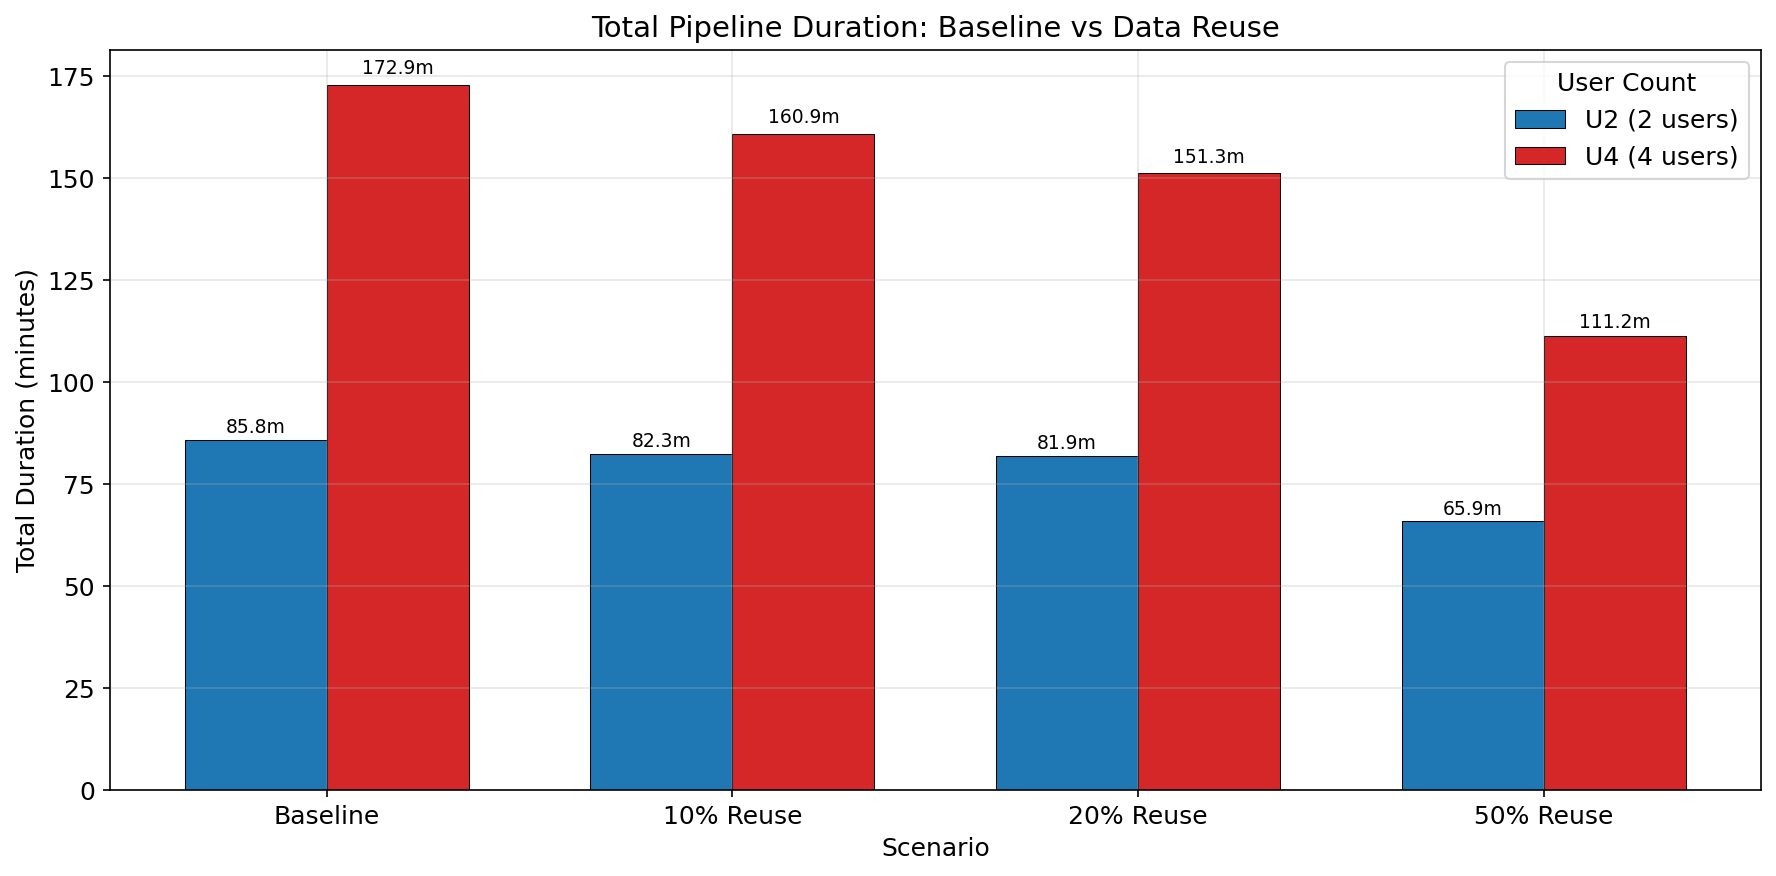

Saved: duration_comparison.pdf


In [36]:
fig, ax = plt.subplots(figsize=(12, 6))

dur_u2 = [get_val(df_results, k, 'duration_min') for k in exp_keys_u2]
dur_u4 = [get_val(df_results, k, 'duration_min') for k in exp_keys_u4]

bars1 = ax.bar(x - width/2, dur_u2, width, label='U2 (2 users)', color=colors_u2, edgecolor='black', linewidth=0.5)
bars2 = ax.bar(x + width/2, dur_u4, width, label='U4 (4 users)', color=colors_u4, edgecolor='black', linewidth=0.5)

for bar in bars1:
    h = bar.get_height()
    if h > 0:
        ax.text(bar.get_x() + bar.get_width()/2., h * 1.01, f'{h:.1f}m', ha='center', va='bottom', fontsize=9)
for bar in bars2:
    h = bar.get_height()
    if h > 0:
        ax.text(bar.get_x() + bar.get_width()/2., h * 1.01, f'{h:.1f}m', ha='center', va='bottom', fontsize=9)

ax.set_xlabel('Scenario')
ax.set_ylabel('Total Duration (minutes)')
ax.set_title('Total Pipeline Duration: Baseline vs Data Reuse')
ax.set_xticks(x)
ax.set_xticklabels(scenarios)
ax.legend(title='User Count')
plt.tight_layout()
plt.savefig('plots/duration_comparison.pdf', bbox_inches='tight')
plt.savefig('plots/duration_comparison.png', bbox_inches='tight')
plt.show()
print('Saved: duration_comparison.pdf')

## 5. Plot 3 — System Throughput

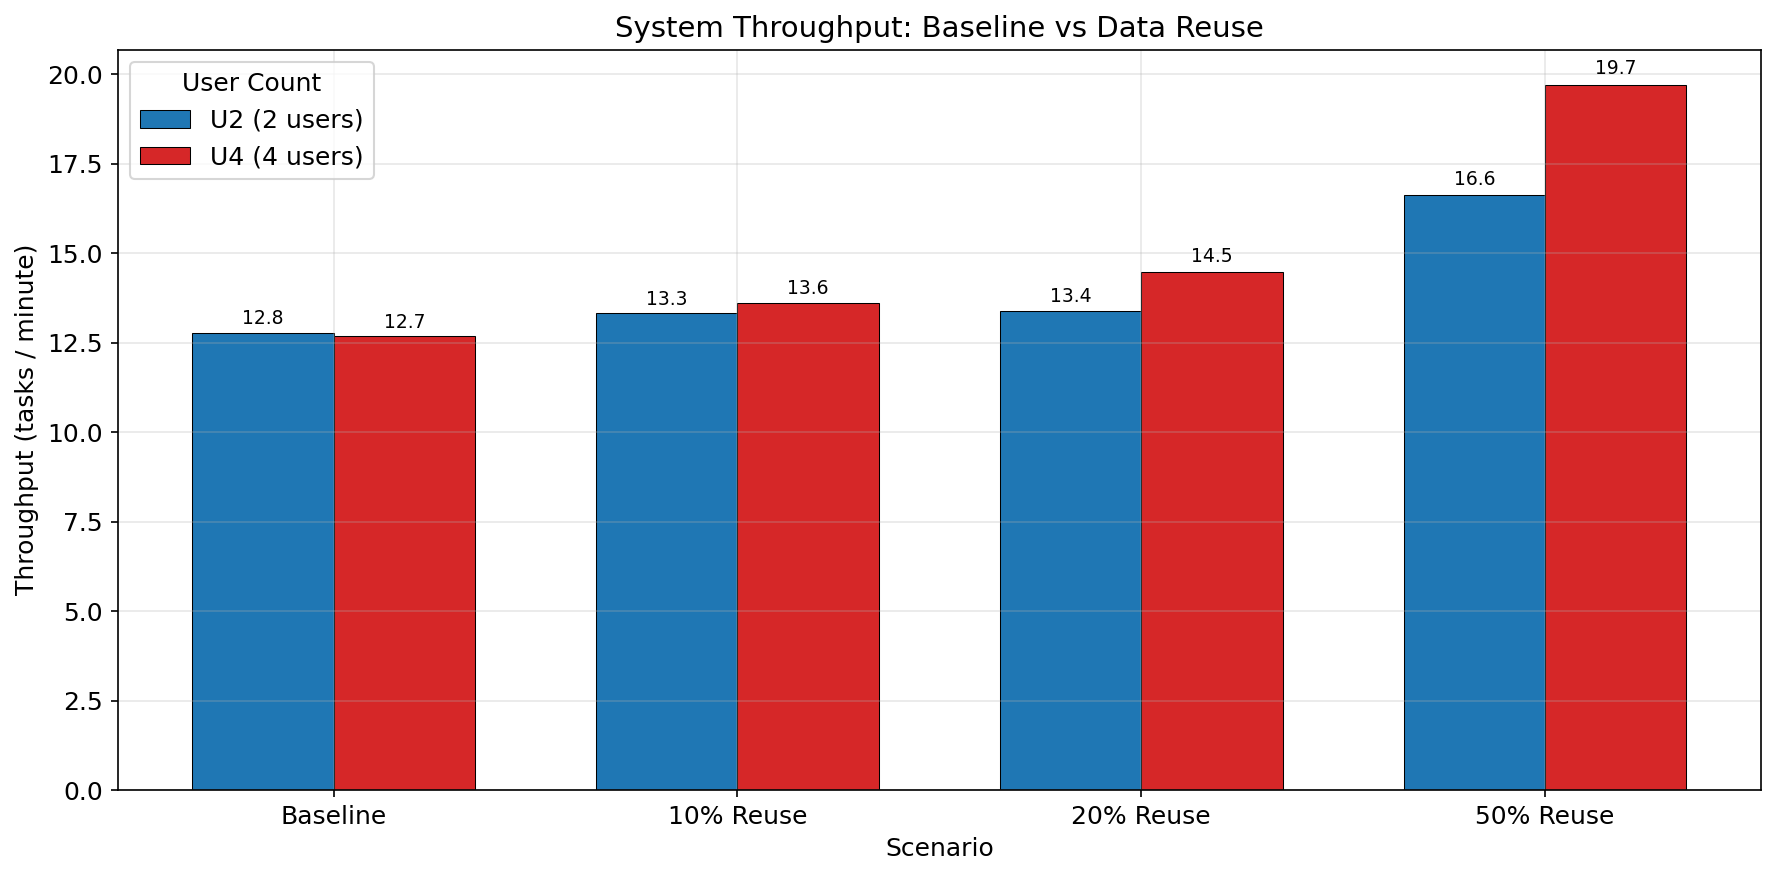

Saved: throughput_comparison.pdf


In [37]:
fig, ax = plt.subplots(figsize=(12, 6))

tp_u2 = [get_val(df_results, k, 'throughput_tasks_min') for k in exp_keys_u2]
tp_u4 = [get_val(df_results, k, 'throughput_tasks_min') for k in exp_keys_u4]

bars1 = ax.bar(x - width/2, tp_u2, width, label='U2 (2 users)', color=colors_u2, edgecolor='black', linewidth=0.5)
bars2 = ax.bar(x + width/2, tp_u4, width, label='U4 (4 users)', color=colors_u4, edgecolor='black', linewidth=0.5)

for bar in bars1:
    h = bar.get_height()
    if h > 0:
        ax.text(bar.get_x() + bar.get_width()/2., h * 1.01, f'{h:.1f}', ha='center', va='bottom', fontsize=9)
for bar in bars2:
    h = bar.get_height()
    if h > 0:
        ax.text(bar.get_x() + bar.get_width()/2., h * 1.01, f'{h:.1f}', ha='center', va='bottom', fontsize=9)

ax.set_xlabel('Scenario')
ax.set_ylabel('Throughput (tasks / minute)')
ax.set_title('System Throughput: Baseline vs Data Reuse')
ax.set_xticks(x)
ax.set_xticklabels(scenarios)
ax.legend(title='User Count')
plt.tight_layout()
plt.savefig('plots/throughput_comparison.pdf', bbox_inches='tight')
plt.savefig('plots/throughput_comparison.png', bbox_inches='tight')
plt.show()
print('Saved: throughput_comparison.pdf')

## 6. Plot 4 — Energy Savings % vs Reuse %

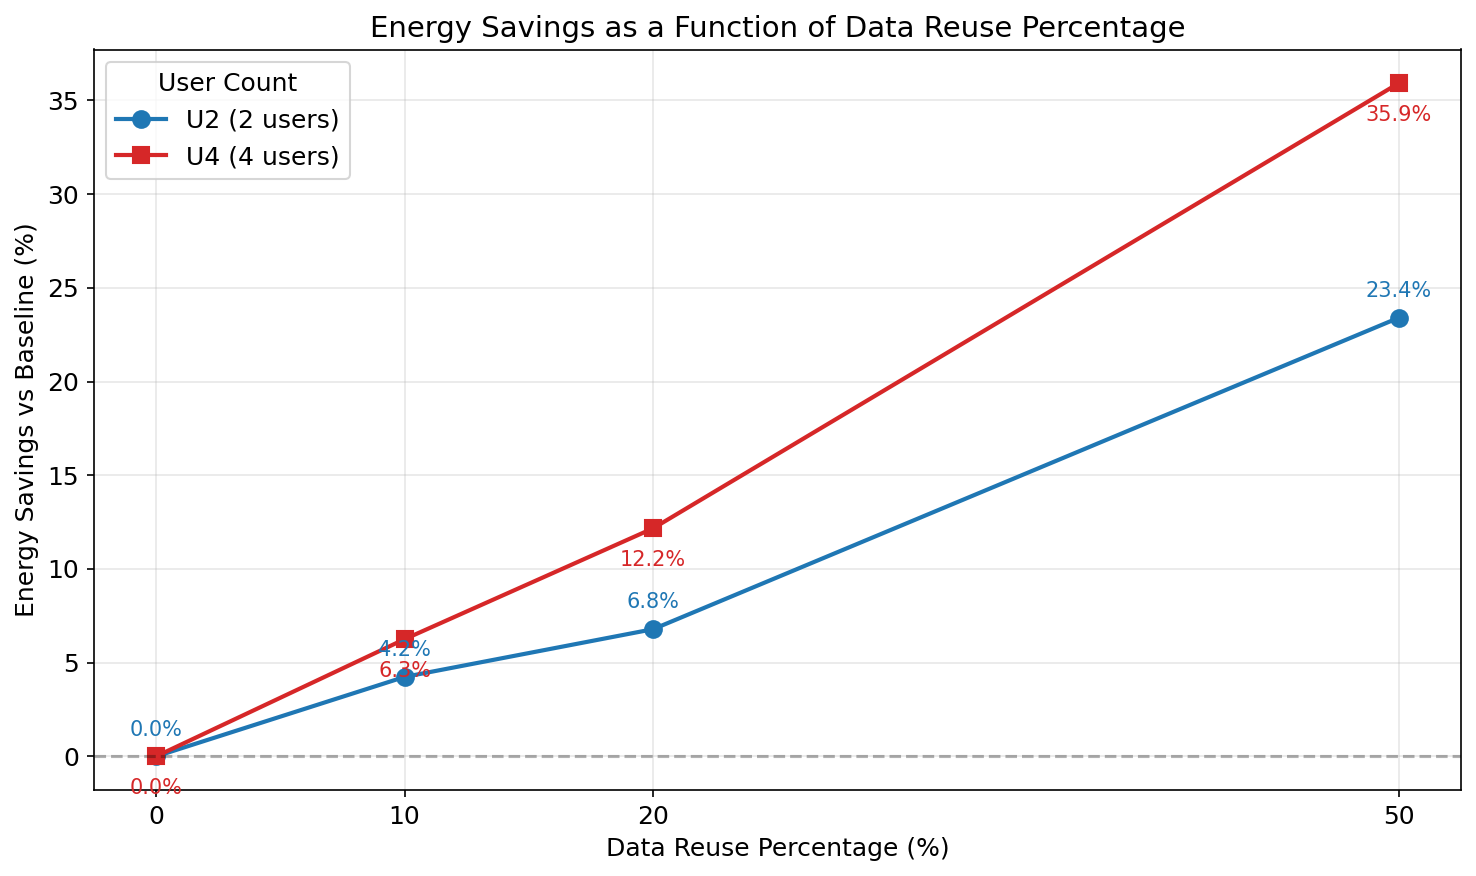

Saved: energy_savings_vs_reuse.pdf


In [39]:
fig, ax = plt.subplots(figsize=(10, 6))

reuse_pcts = [0, 10, 20, 50]

baseline_u2 = get_val(df_results, 'Baseline U2', 'energy_joules')
baseline_u4 = get_val(df_results, 'Baseline U4', 'energy_joules')

savings_u2 = [0] + [
    (baseline_u2 - get_val(df_results, f'Reuse U2 {p}%', 'energy_joules')) / baseline_u2 * 100
    if baseline_u2 > 0 else 0
    for p in [10, 20, 50]
]
savings_u4 = [0] + [
    (baseline_u4 - get_val(df_results, f'Reuse U4 {p}%', 'energy_joules')) / baseline_u4 * 100
    if baseline_u4 > 0 else 0
    for p in [10, 20, 50]
]

ax.plot(reuse_pcts, savings_u2, 'o-', color='#1f77b4', linewidth=2, markersize=8, label='U2 (2 users)')
ax.plot(reuse_pcts, savings_u4, 's-', color='#d62728', linewidth=2, markersize=8, label='U4 (4 users)')

for p, s in zip(reuse_pcts, savings_u2):
    ax.annotate(f'{s:.1f}%', (p, s), textcoords='offset points', xytext=(0, 10), ha='center', fontsize=10, color='#1f77b4')
for p, s in zip(reuse_pcts, savings_u4):
    ax.annotate(f'{s:.1f}%', (p, s), textcoords='offset points', xytext=(0, -18), ha='center', fontsize=10, color='#d62728')

ax.set_xlabel('Data Reuse Percentage (%)')
ax.set_ylabel('Energy Savings vs Baseline (%)')
ax.set_title('Energy Savings as a Function of Data Reuse Percentage')
ax.set_xticks(reuse_pcts)
ax.legend(title='User Count')
ax.axhline(y=0, color='black', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.savefig('plots/energy_savings_vs_reuse.pdf', bbox_inches='tight')
plt.savefig('plots/energy_savings_vs_reuse.png', bbox_inches='tight')
plt.show()
print('Saved: energy_savings_vs_reuse.pdf')

## 7. Summary Table

In [31]:
print(df_results[['experiment', 'energy_joules', 'duration_min', 'throughput_tasks_min']].to_string(index=False))
df_results.to_csv('plots/experiment_summary.csv', index=False)
print('\nSaved: experiment_summary.csv')

  experiment  energy_joules  duration_min  throughput_tasks_min
 Baseline U2  214994.246659     85.782396             12.776514
 Baseline U4  432183.213727    172.888847             12.678666
Reuse U2 10%  205876.000566     82.288131             13.319053
Reuse U2 20%  200400.918843     81.895873             13.382848
Reuse U2 50%  164672.364339     65.863536             16.640467
Reuse U4 10%  405157.360542    160.883493             13.624766
Reuse U4 20%  379589.154530    151.285818             14.489131
Reuse U4 50%  276942.090330    111.211528             19.710187

Saved: experiment_summary.csv


In [32]:
df = load_csv(EXPERIMENTS['Baseline U2'], 'kepler_node_cpu_power_raw.csv')
print(df['treatment'].value_counts())
print(df['kepler_node_cpu_power_raw'].describe())

treatment
Treatment      2060
NoTreatment      24
Name: count, dtype: int64
count      2084.000000
mean      78616.774300
std       56357.275867
min           0.167419
25%       34636.719145
50%       73526.590824
75%      122863.850109
max      192198.683873
Name: kepler_node_cpu_power_raw, dtype: float64


In [13]:
for name, folder in EXPERIMENTS.items():
    df = load_csv(folder, 'kepler_node_cpu_power_raw.csv')
    df = df[df['treatment'] == 'Treatment'].sort_values('timestamp.1')
    col = 'kepler_node_cpu_power_raw'
    deltas = df[col].diff()
    n_resets = (deltas < 0).sum()
    print(f"{name}: resets={n_resets}, total_deltas={len(deltas)}, energy={deltas[deltas>0].sum():.0f}J")

Baseline U2: resets=954, total_deltas=2060, energy=73549858J
Baseline U4: resets=1960, total_deltas=4148, energy=185789432J
Reuse U2 10%: resets=944, total_deltas=1972, energy=106321288J
Reuse U2 20%: resets=937, total_deltas=1960, energy=111963248J
Reuse U2 50%: resets=746, total_deltas=1580, energy=101990753J
Reuse U4 10%: resets=1815, total_deltas=3860, energy=241694320J
Reuse U4 20%: resets=1714, total_deltas=3624, energy=234846492J
Reuse U4 50%: resets=1258, total_deltas=2672, energy=113826793J


In [33]:
df = load_csv(EXPERIMENTS['Baseline U2'], 'kepler_node_cpu_power_sum.csv')
print(df.columns.tolist())
print(df.head(3))
print(df['treatment'].value_counts())


['timestamp', 'timestamp.1', 'kepler_node_cpu_power_sum', 'layer', 'unit', 'treatment']
                             timestamp   timestamp.1  \
0  2026-05-28 06:56:27.859999895+00:00  1.779951e+09   
1  2026-05-28 06:56:37.859999895+00:00  1.779951e+09   
2  2026-05-28 06:56:47.859999895+00:00  1.779951e+09   

   kepler_node_cpu_power_sum    layer   unit    treatment  
0                  13.014478  cluster  watts  NoTreatment  
1                  13.258423  cluster  watts  NoTreatment  
2                  13.332550  cluster  watts  NoTreatment  
treatment
Treatment      515
NoTreatment      6
Name: count, dtype: int64


In [15]:
for name, folder in list(EXPERIMENTS.items())[:1]:
    data_dir = Path(folder) / "data"
    for f in sorted(data_dir.iterdir()):
        df = pd.read_csv(f)
        treatment = df[df['treatment'] == 'Treatment'] if 'treatment' in df.columns else df
        val_col = [c for c in df.columns if c not in ['timestamp', 'timestamp.1', 'treatment', 'layer', 'unit', '__name__', 'container', 'endpoint', 'instance', 'job', 'namespace', 'node_name', 'path', 'pod', 'service', 'zone']]
        print(f"{f.name}: rows={len(treatment)}, cols={val_col}")

kepler_all_pod_cpu_power_watts.csv: rows=515, cols=['kepler_all_pod_cpu_power_watts']
kepler_node_cpu_power_raw.csv: rows=2060, cols=['kepler_node_cpu_power_raw']
kepler_node_cpu_power_sum.csv: rows=515, cols=['kepler_node_cpu_power_sum']
kepler_pod_cpu_power_joules_raw.csv: rows=855, cols=['pod_id', 'kepler_pod_cpu_power_joules_raw']
node_network_receive_bytes.csv: rows=6551, cols=['device', 'node', 'node_network_receive_bytes']
node_network_receive_bytes_raw.csv: rows=6775, cols=['device', 'node', 'node_network_receive_bytes_raw']
node_network_transmit_bytes.csv: rows=6551, cols=['device', 'node', 'node_network_transmit_bytes']
node_network_transmit_bytes_raw.csv: rows=6775, cols=['device', 'node', 'node_network_transmit_bytes_raw']
pod_fs_reads_bytes.csv: rows=530, cols=['pod_fs_reads_bytes']
pod_fs_write_bytes.csv: rows=530, cols=['pod_fs_write_bytes']
pod_memory_usage.csv: rows=910, cols=['pod_memory_usage']
pod_network_receive_bytes.csv: rows=780, cols=['pod_network_receive_bytes

In [34]:
import pandas as pd
trace = pd.read_csv('~/Desktop/paper_experiments/baseline_sequential/traces/user1_baseline_20260528_065657/trace.txt', sep='\t')
print(trace.columns.tolist())
print(trace.head(3))


['task_id', 'hash', 'native_id', 'name', 'status', 'exit', 'submit', 'duration', 'realtime', '%cpu', 'peak_rss', 'peak_vmem', 'rchar', 'wchar']
   task_id       hash                                  native_id  \
0        2  73/ae2470  nf-73ae24708b5e159d5b5e1a65ede4de8a-d5b72   
1        5  3c/414be4  nf-3c414be4b820fb21bdf3222a9914d46e-1fef6   
2        7  9c/51c115  nf-9c51c1152d7841578466eda0937fdca0-0df86   

                                                name     status  exit  \
0  NFCORE_RNASEQ:PREPARE_GENOME:GUNZIP_ADDITIONAL...  COMPLETED     0   
1  NFCORE_RNASEQ:RNASEQ:FASTQ_QC_TRIM_FILTER_SETS...  COMPLETED     0   
2  NFCORE_RNASEQ:RNASEQ:FASTQ_QC_TRIM_FILTER_SETS...  COMPLETED     0   

                    submit duration realtime   %cpu peak_rss peak_vmem  \
0  2026-05-28 06:57:12.733     1.3s     93ms  38.1%   3.5 MB    4.6 MB   
1  2026-05-28 06:57:12.696     1.3s       1s  77.5%   3.1 MB    4.3 MB   
2  2026-05-28 06:57:12.770     1.2s       1s  75.1%   3.1 MB    4.3 

In [21]:
import json
import pandas as pd
import numpy as np
from pathlib import Path

BASE_DIR = Path('~/Desktop/paper_experiments').expanduser()

EXPERIMENTS = {
    'Baseline U2': BASE_DIR / 'baseline_sequential' / 'nextflow_rnaseq_partial_resume_2026_05_28_06_56_27_df3720c9',
    'Baseline U4': BASE_DIR / 'baseline_sequential' / 'nextflow_rnaseq_partial_resume_2026_05_28_08_23_15_380543a9',
    'Reuse U2 10%': BASE_DIR / 'reuse_sequential' / 'nextflow_rnaseq_partial_resume_2026_05_27_10_34_11_31e60571',
    'Reuse U2 20%': BASE_DIR / 'reuse_sequential' / 'nextflow_rnaseq_partial_resume_2026_05_27_12_07_32_3d7b68ca',
    'Reuse U2 50%': BASE_DIR / 'reuse_sequential' / 'nextflow_rnaseq_partial_resume_2026_05_27_13_53_11_2e5a48b1',
    'Reuse U4 10%': BASE_DIR / 'reuse_sequential' / 'nextflow_rnaseq_partial_resume_2026_05_27_15_19_12_fb52d4d4',
    'Reuse U4 20%': BASE_DIR / 'reuse_sequential' / 'nextflow_rnaseq_partial_resume_2026_05_27_18_29_51_f387afe0',
    'Reuse U4 50%': BASE_DIR / 'reuse_sequential' / 'nextflow_rnaseq_partial_resume_2026_05_27_22_10_43_9bb8ec96',
}

tasks_per_user = 548

def load_csv(folder, name):
    path = Path(folder) / 'data' / name
    return pd.read_csv(path) if path.exists() else None

def load_run_json(folder):
    p = Path(folder) / 'run.json'
    return json.loads(p.read_text()) if p.exists() else None

def get_treatment(df):
    if 'treatment' in df.columns:
        return df[df['treatment'] == 'Treatment'].copy()
    return df.copy()

def get_energy(folder):
    df = load_csv(folder, 'kepler_node_cpu_power_sum.csv')
    if df is not None:
        return get_treatment(df)['kepler_node_cpu_power_sum'].sum() * 10
    return None

def get_duration(folder):
    rj = load_run_json(folder)
    return rj.get('treatment_duration') if rj else None

print(f"{'Experiment':<20} {'Energy(J)':>12} {'Energy(kJ)':>12} {'Duration(s)':>12} {'Duration(min)':>14} {'Throughput(t/min)':>18} {'Users':>6}")
print('-' * 90)

results = []
for name, folder in EXPERIMENTS.items():
    energy = get_energy(folder)
    duration = get_duration(folder)
    u = 2 if 'U2' in name else 4
    dur_min = duration / 60 if duration else None
    throughput = (u * tasks_per_user) / dur_min if dur_min else None
    results.append({'experiment': name, 'users': u, 'energy_j': energy,
                    'duration_min': dur_min, 'throughput': throughput})
    print(f"{name:<20} {energy:>12.1f} {energy/1000:>12.2f} {duration:>12.1f} {dur_min:>14.2f} {throughput:>18.2f} {u:>6}")

df = pd.DataFrame(results)

print('\n--- ENERGY SAVINGS vs BASELINE ---')
for u_label, base_key in [('U2', 'Baseline U2'), ('U4', 'Baseline U4')]:
    base_e = df[df.experiment == base_key]['energy_j'].values[0]
    base_t = df[df.experiment == base_key]['throughput'].values[0]
    base_d = df[df.experiment == base_key]['duration_min'].values[0]
    for pct in [10, 20, 50]:
        key = f'Reuse {u_label} {pct}%'
        row = df[df.experiment == key]
        if not row.empty:
            e = row['energy_j'].values[0]
            t = row['throughput'].values[0]
            d = row['duration_min'].values[0]
            e_save = (base_e - e) / base_e * 100
            t_gain = (t - base_t) / base_t * 100
            d_save = (base_d - d) / base_d * 100
            print(f"{key}: energy_saving={e_save:.1f}%, throughput_gain={t_gain:.1f}%, duration_saving={d_save:.1f}%")

Experiment              Energy(J)   Energy(kJ)  Duration(s)  Duration(min)  Throughput(t/min)  Users
------------------------------------------------------------------------------------------
Baseline U2              214994.2       214.99       5146.9          85.78              12.78      2
Baseline U4              432183.2       432.18      10373.3         172.89              12.68      4
Reuse U2 10%             205876.0       205.88       4937.3          82.29              13.32      2
Reuse U2 20%             200400.9       200.40       4913.8          81.90              13.38      2
Reuse U2 50%             164672.4       164.67       3951.8          65.86              16.64      2
Reuse U4 10%             405157.4       405.16       9653.0         160.88              13.62      4
Reuse U4 20%             379589.2       379.59       9077.1         151.29              14.49      4
Reuse U4 50%             276942.1       276.94       6672.7         111.21              19.71      4


In [22]:
df = pd.read_csv(BASE_DIR / 'baseline_sequential' / 'nextflow_rnaseq_partial_resume_2026_05_28_06_56_27_df3720c9' / 'data' / 'kepler_pod_cpu_power_joules_raw.csv')
print(df.columns.tolist())
print(df['pod_id'].unique() if 'pod_id' in df.columns else 'no pod_id column')
print(df.head(5))

['timestamp', 'pod_id', 'timestamp.1', 'kepler_pod_cpu_power_joules_raw', 'layer', 'unit', 'treatment']
<StringArray>
['0021e2fa-8f53-4484-b809-3bb0020c1457',
 '003c79e5-2a03-4555-96be-5e6dbd74fe97',
 '02b6c0c3-c994-4894-9b5c-f733c1aff8d2',
 '03abb7c9-3685-4653-bb37-44f6dbdf1cf6',
 '0559a620-5412-4acf-98d6-6c782fa2ce37',
 '07a80e02-4b17-4164-86c6-b322712565de',
 '0a67e289-2b11-4d69-ae0f-83eb6e012234',
 '0b9f4c3d-5a14-452a-9c06-7ee73796f448',
 '0bc2c5eb-daa0-41c0-9e31-2b5970c8ab7c',
 '0d660711-09f9-4353-88f5-3b4fbad07fed',
 ...
 'eced0ffe-5619-4e87-9663-ac439cc41189',
 'eda1199e-62f7-4249-bdb9-96c6e5cb8286',
 'efd2586d-d6b4-42c8-9588-840185d6323a',
 'f2da9e93-3a0b-4ea0-96ab-aca16bc979f0',
 'f3121730-4b01-4d10-be50-2535be31c150',
 'f6828129-e7d3-4358-941a-435cb60c903f',
 'f6fa8963-6e00-42ca-b814-0b5aaeeebfaf',
 'f7fec60a-48e5-4dcc-937a-8b89f3caa909',
 'f9a827a6-d03a-4a2d-a847-b4dc1fae3e0d',
 'fa674c82-7351-47e9-be39-1833c83333b6']
Length: 168, dtype: str
                             time

In [ ]:
### The transofmration service reuse plots ##############

In [40]:

import json
import pandas as pd
import numpy as np
from pathlib import Path

BASE_DIR = Path('~/Desktop/paper_experiments').expanduser()

EXPERIMENTS_POD = {
    'Baseline U2': BASE_DIR / 'baseline_sequential' / 'nextflow_rnaseq_partial_resume_2026_05_28_06_56_27_df3720c9',
    'Baseline U4': BASE_DIR / 'baseline_sequential' / 'nextflow_rnaseq_partial_resume_2026_05_28_08_23_15_380543a9',
    'Pod Service U2': BASE_DIR / 'pod_service' / 'nextflow_rnaseq_partial_resume_2026_05_29_08_49_05_177a4c52',
    'Pod Service U4': BASE_DIR / 'pod_service' / 'nextflow_rnaseq_partial_resume_2026_05_29_09_47_52_7125d12a',
}

def load_csv(folder, name):
    path = Path(folder) / 'data' / name
    return pd.read_csv(path) if path.exists() else None

def load_run_json(folder):
    p = Path(folder) / 'run.json'
    return json.loads(p.read_text()) if p.exists() else None

def get_treatment(df):
    if 'treatment' in df.columns:
        return df[df['treatment'] == 'Treatment'].copy()
    return df.copy()

def get_energy(folder):
    df = load_csv(folder, 'kepler_node_cpu_power_sum.csv')
    if df is not None:
        return get_treatment(df)['kepler_node_cpu_power_sum'].sum() * 10
    return None

def get_duration(folder):
    rj = load_run_json(folder)
    return rj.get('treatment_duration') if rj else None

tasks_per_user = 548

print(f"{'Experiment':<20} {'Energy(kJ)':>12} {'Duration(min)':>14} {'Throughput(t/min)':>18}")
print('-' * 70)

results = []
for name, folder in EXPERIMENTS_POD.items():
    energy = get_energy(folder)
    duration = get_duration(folder)
    u = 2 if 'U2' in name else 4
    dur_min = duration / 60 if duration else None
    throughput = (u * tasks_per_user) / dur_min if dur_min else None
    results.append({'experiment': name, 'users': u, 'energy_j': energy,
                    'energy_kj': energy/1000 if energy else None,
                    'duration_min': dur_min, 'throughput': throughput})
    print(f"{name:<20} {energy/1000:>12.2f} {dur_min:>14.2f} {throughput:>18.2f}")

df = pd.DataFrame(results)

print('\n--- SAVINGS vs BASELINE ---')
for u_label, base_key in [('U2', 'Baseline U2'), ('U4', 'Baseline U4')]:
    base_e = df[df.experiment == base_key]['energy_j'].values[0]
    base_t = df[df.experiment == base_key]['throughput'].values[0]
    base_d = df[df.experiment == base_key]['duration_min'].values[0]
    key = f'Pod Service {u_label}'
    row = df[df.experiment == key]
    if not row.empty:
        e = row['energy_j'].values[0]
        t = row['throughput'].values[0]
        d = row['duration_min'].values[0]
        e_save = (base_e - e) / base_e * 100
        t_gain = (t - base_t) / base_t * 100
        d_save = (base_d - d) / base_d * 100
        print(f"{key}: energy_saving={e_save:.1f}%, throughput_gain={t_gain:.1f}%, duration_saving={d_save:.1f}%")

Experiment             Energy(kJ)  Duration(min)  Throughput(t/min)
----------------------------------------------------------------------
Baseline U2                214.99          85.78              12.78
Baseline U4                432.18         172.89              12.68
Pod Service U2             182.41          57.78              18.97
Pod Service U4             365.87         115.60              18.96

--- SAVINGS vs BASELINE ---
Pod Service U2: energy_saving=15.2%, throughput_gain=48.5%, duration_saving=32.6%
Pod Service U4: energy_saving=15.3%, throughput_gain=49.6%, duration_saving=33.1%
